# 03_bmc_springer_nature: BMC / Springer Nature journals (BMC Infectious Diseases, Parasites & Vectors, ...)

Participant-level supplementary files ("MOESM"), found through Europe PMC; Springer Nature also mirrors them on Figshare.

**How the journal datasets were found.** Europe PMC was searched for every open-access paper with supplementary files whose title/abstract mentions Toxoplasma, toxoplasmosis, gondii, TORCH, multiplex serology or pathogen burden (3,482 papers). Their data files (xlsx, xls, csv, sav, dta, ...) were downloaded from the PMC Open Access S3 bucket (1,407 papers had data files, 6.6 GB) and every table with >= 80 rows was scanned for a Toxoplasma result column (607 tables, 285 papers). Human, participant-level tables with at least two IgG classes were then checked by hand. Scripts: `datasets/_harvest/`.

**Same protocol for every dataset** (`datasets/common/protocol.py`): label = Toxoplasma IgG positive; every column that measures Toxoplasma itself (IgM, avidity, titre, OD, PCR, other kits) and identifiers are removed; logistic regression, random forest and XGBoost; ROC-AUC from 5-fold x 3 repeated stratified cross-validation with preprocessing inside the folds. Datasets with fewer than 20 positives or 20 negatives are catalogued but not evaluated.

**Sections:** setup → helpers → one section per dataset (where it comes from, how the label is coded, what is removed) → build and evaluate → chart. Outputs are written to `raw/`, `processed/`, `results.csv`, `DATASETS.md`.

In [1]:
# Setup: run from the repository root and load the shared protocol (datasets/common/*.ipynb)
import os, sys, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'; warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
sys.path.insert(0, 'scripts')          # curated loaders: scripts/external_datasets.py, us_datasets.py, europe_datasets.py
%run -i datasets/common/protocol.ipynb
%run -i datasets/common/folder_tools.ipynb
import pandas as pd
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)
HERE = 'datasets/03_bmc_springer_nature'
print('working directory:', os.getcwd())

working directory: /home/claude/toxo


**Notes on this source.** BMC / Springer Nature journals (BMC Infectious Diseases, Parasites & Vectors, ...): participant-level supplementary files
(Springer Nature also mirrors these on Figshare as 'MOESM' files; they are filed here, under the journal).

## Helpers (curated loaders and source-specific functions)

In [2]:
import external_datasets as ex

## Datasets

Each cell adds one dataset to `CONFIG`: `source` = where the raw file comes from, `label` / `pos` / `neg` = how the Toxoplasma IgG result is coded, `drop` = extra columns removed (leakage, identifiers, outcomes), `loader` = a hand-written loader in `scripts/` for datasets curated earlier.

In [3]:
CONFIG = []

### iran_suicide_attempters

**Epidemiological aspects and cytokine profiles of T. gondii in suicide attempters, Lorestan**  
Iran · Suicide attempters and controls · DOI/ID: `10.1186/s12879-025-11200-1`

In [4]:
CONFIG.append(dict(key='iran_suicide_attempters', title='Epidemiological aspects and cytokine profiles of T. gondii in suicide attempters, Lorestan',
     doi='10.1186/s12879-025-11200-1', setting='Suicide attempters and controls', country='Iran',
     source=('pmc', 'PMC12210893'), file='12879_2025_11200_MOESM1_ESM.sav', loader=ex.iran_suicide))

### colombia_thyroid

**Association between T. gondii infection and thyroid dysfunction: case-control study**  
Colombia · Thyroid disease cases and controls · DOI/ID: `10.1186/s12879-019-4450-0`

In [5]:
CONFIG.append(dict(key='colombia_thyroid', title='Association between T. gondii infection and thyroid dysfunction: case-control study',
     doi='10.1186/s12879-019-4450-0', setting='Thyroid disease cases and controls', country='Colombia',
     source=('pmc', 'PMC6751844'), file='12879_2019_4450_MOESM1_ESM.xls', label='IgGTg', pos=['positivo'], neg=['negativo'],
     drop=['NUMBER_CASE', 'Number']))

### mexico_liver_disease

**T. gondii infection and liver disease: case-control study, northern Mexico**  
Mexico · Liver disease patients and controls · DOI/ID: `10.1186/1756-3305-4-75`

16 positives: below the 20-case minimum, catalogued only.

In [6]:
CONFIG.append(dict(key='mexico_liver_disease', title='T. gondii infection and liver disease: case-control study, northern Mexico',
     doi='10.1186/1756-3305-4-75', setting='Liver disease patients and controls', country='Mexico',
     source=('pmc', 'PMC3105944'), file='1756-3305-4-75-S2.XLS', label='Anti-T. gondii', pos=['positive'], neg=['negative'],
     note='16 positives: below the 20-case minimum, catalogued only.'))

## Build and evaluate

Downloads (or copies) each raw file into `raw/`, builds `processed/<dataset>.csv`, removes leakage columns, then runs logistic regression, random forest and XGBoost with 5-fold x 3 cross-validation.

In [7]:
res = run(HERE, CONFIG)

iran_suicide_attempters            n=   500 pos=  153 feats= 12 best AUC=0.632 (LogReg)


colombia_thyroid                   n=   704 pos=   59 feats=  5 best AUC=0.538 (LogReg)
mexico_liver_disease               n=   156 pos=   16 feats= 54 best AUC=nan (not evaluated (fewer than 20 positives or negatives))


In [8]:
cols = ['dataset', 'country', 'n', 'positives', 'prevalence', 'n_features', 'LogReg_auc', 'RandomForest_auc', 'XGBoost_auc',
        'best_auc', 'best_model']
res[[c for c in cols if c in res]]

,dataset,country,n,positives,prevalence,n_features,LogReg_auc,RandomForest_auc,XGBoost_auc,best_auc,best_model
0,iran_suicide_attempters,Iran,500,153,0.306,12,0.632,0.631,0.625,0.632,LogReg
1,colombia_thyroid,Colombia,704,59,0.084,5,0.538,0.484,0.483,0.538,LogReg
2,mexico_liver_disease,Mexico,156,16,0.103,54,NaN,NaN,NaN,NaN,not evaluated (fewer than 20 positives or negatives)


## Chart

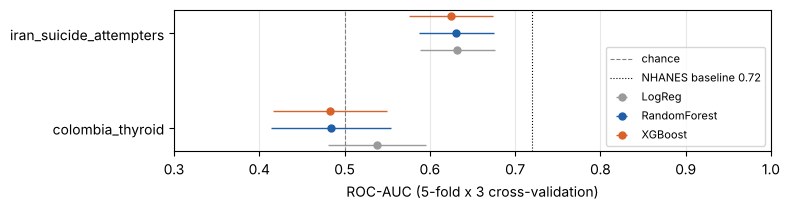

In [9]:
# ROC-AUC per dataset and model (error bars: SD over the 15 CV folds)
import matplotlib.pyplot as plt
r = res[res.best_auc.notna()].sort_values('best_auc')
if len(r):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(r) + 1.2))
    for k, (m, c) in enumerate([('LogReg', '#9a9a9a'), ('RandomForest', '#1f5fa8'), ('XGBoost', '#d9622b')]):
        ax.errorbar(r[f'{m}_auc'], [i + (k - 1) * 0.18 for i in range(len(r))], xerr=r[f'{m}_sd'], fmt='o', ms=5,
                    color=c, label=m, elinewidth=1)
    ax.axvline(0.5, ls='--', color='grey', lw=0.8, label='chance')
    ax.axvline(0.72, ls=':', color='black', lw=0.8, label='NHANES baseline 0.72')
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.dataset)
    ax.set_xlabel('ROC-AUC (5-fold x 3 cross-validation)'); ax.set_xlim(0.3, 1.0)
    ax.legend(loc='lower right', fontsize=8); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout(); plt.show()

## What was removed as leakage, and the inputs used

In [10]:
res[['dataset', 'removed_as_leakage', 'features']]

,dataset,removed_as_leakage,features
0,iran_suicide_attempters,,"suicide_attempt_group, sex_code, age_group, education, p..."
1,colombia_thyroid,,"Thyroid, CASE_CONTROL, Age group, Birthplace, Residence"
2,mexico_liver_disease,"Anti-T. gondii.2, Anti-T. gondii.3","nan, nan.2, Age, Gender, Birth place, Residence, 1-Urban..."
